# Ciclo de vida del modelo: chatbot de preguntas frecuentes UPQ

**Objetivo:** comparar cuatro clasificadores supervisados sobre el mismo corpus, con el
mismo procedimiento de evaluación (validación cruzada estratificada, F1 macro y matrices
de confusión), y justificar cuál se usa en el chatbot.

**Restricción de la tarea:** solo aprendizaje supervisado clásico con TF-IDF y
scikit-learn, todo local.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

RAIZ = Path.cwd().parent
assert (RAIZ / "src").exists(), f"No encuentro src/ en {RAIZ}; ¿abriste el notebook desde notebooks/?"
sys.path.insert(0, str(RAIZ))

from src.preprocesamiento import limpiar_texto

print("Proyecto:", RAIZ)

Proyecto: /home/baz/Downloads/repos/chatbot-upq


365 ejemplos, 18 intenciones
intencion
admision                  24
calendario_escolar        21
becas                     20
saludo                    20
despedida                 20
agradecimiento            20
oferta_educativa          20
costos_pagos              20
reinscripcion             20
estadias                  20
servicio_social           20
titulacion                20
ingles_idiomas            20
movilidad_intercambio     20
servicios_escolares       20
ubicacion_transporte      20
contacto_horarios         20
biblioteca_actividades    20
Name: count, dtype: int64


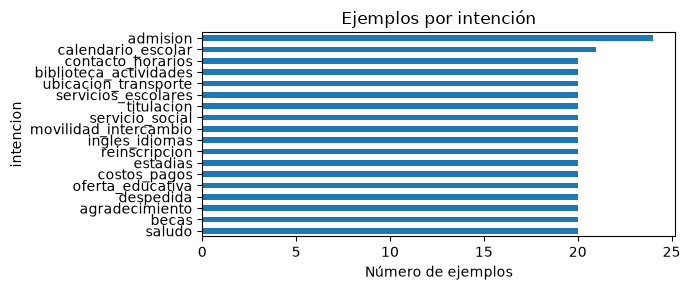

In [2]:
corpus = pd.read_csv(RAIZ / "data" / "corpus_upq.csv")
conteo = corpus["intencion"].value_counts()
print(f"{len(corpus)} ejemplos, {corpus['intencion'].nunique()} intenciones")
print(conteo)

conteo.sort_values().plot.barh(figsize=(7, 3), title="Ejemplos por intención")
plt.xlabel("Número de ejemplos")
plt.tight_layout()
plt.show()

In [3]:
corpus["texto_limpio"] = corpus["texto"].map(limpiar_texto)
corpus[["texto", "texto_limpio"]].sample(5, random_state=42)

,texto,texto_limpio
193,requisitos para la estadía,requisitos para la estadia
33,buenas,buenas
15,calendario escolar 2026,calendario escolar 2026
309,¿Hay transporte escolar?,hay transporte escolar
57,nos vemos,nos vemos


In [4]:
X = corpus["texto_limpio"]
y = corpus["intencion"]

n_splits = min(5, y.value_counts().min())
folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
print(f"Validación cruzada estratificada con {n_splits} folds")


def tfidf():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)


modelos = {
    "LogisticRegression (C=1)": LogisticRegression(max_iter=1000, random_state=42),
    "LogisticRegression (C=10)": LogisticRegression(C=10, max_iter=1000, random_state=42),
    "LinearSVC": LinearSVC(random_state=42),
    "MultinomialNB": MultinomialNB(),
    "KNN (coseno, k=3)": KNeighborsClassifier(n_neighbors=3, metric="cosine"),
}
pipelines = {n: Pipeline([("tfidf", tfidf()), ("clf", clf)]) for n, clf in modelos.items()}

filas = []
for nombre, pipe in pipelines.items():
    r = cross_validate(pipe, X, y, cv=folds, scoring=["f1_macro", "accuracy"])
    filas.append({
        "modelo": nombre,
        "f1_macro": r["test_f1_macro"].mean(),
        "f1_desv": r["test_f1_macro"].std(),
        "accuracy": r["test_accuracy"].mean(),
        "acc_desv": r["test_accuracy"].std(),
    })

resultados = pd.DataFrame(filas).sort_values("f1_macro", ascending=False).reset_index(drop=True)
resultados.round(3)

Validación cruzada estratificada con 5 folds


,modelo,f1_macro,f1_desv,accuracy,acc_desv
0,LogisticRegression (C=10),0.781,0.061,0.789,0.056
1,LinearSVC,0.762,0.056,0.773,0.051
2,LogisticRegression (C=1),0.747,0.042,0.756,0.036
3,MultinomialNB,0.694,0.039,0.710,0.029
4,"KNN (coseno, k=3)",0.572,0.043,0.584,0.040


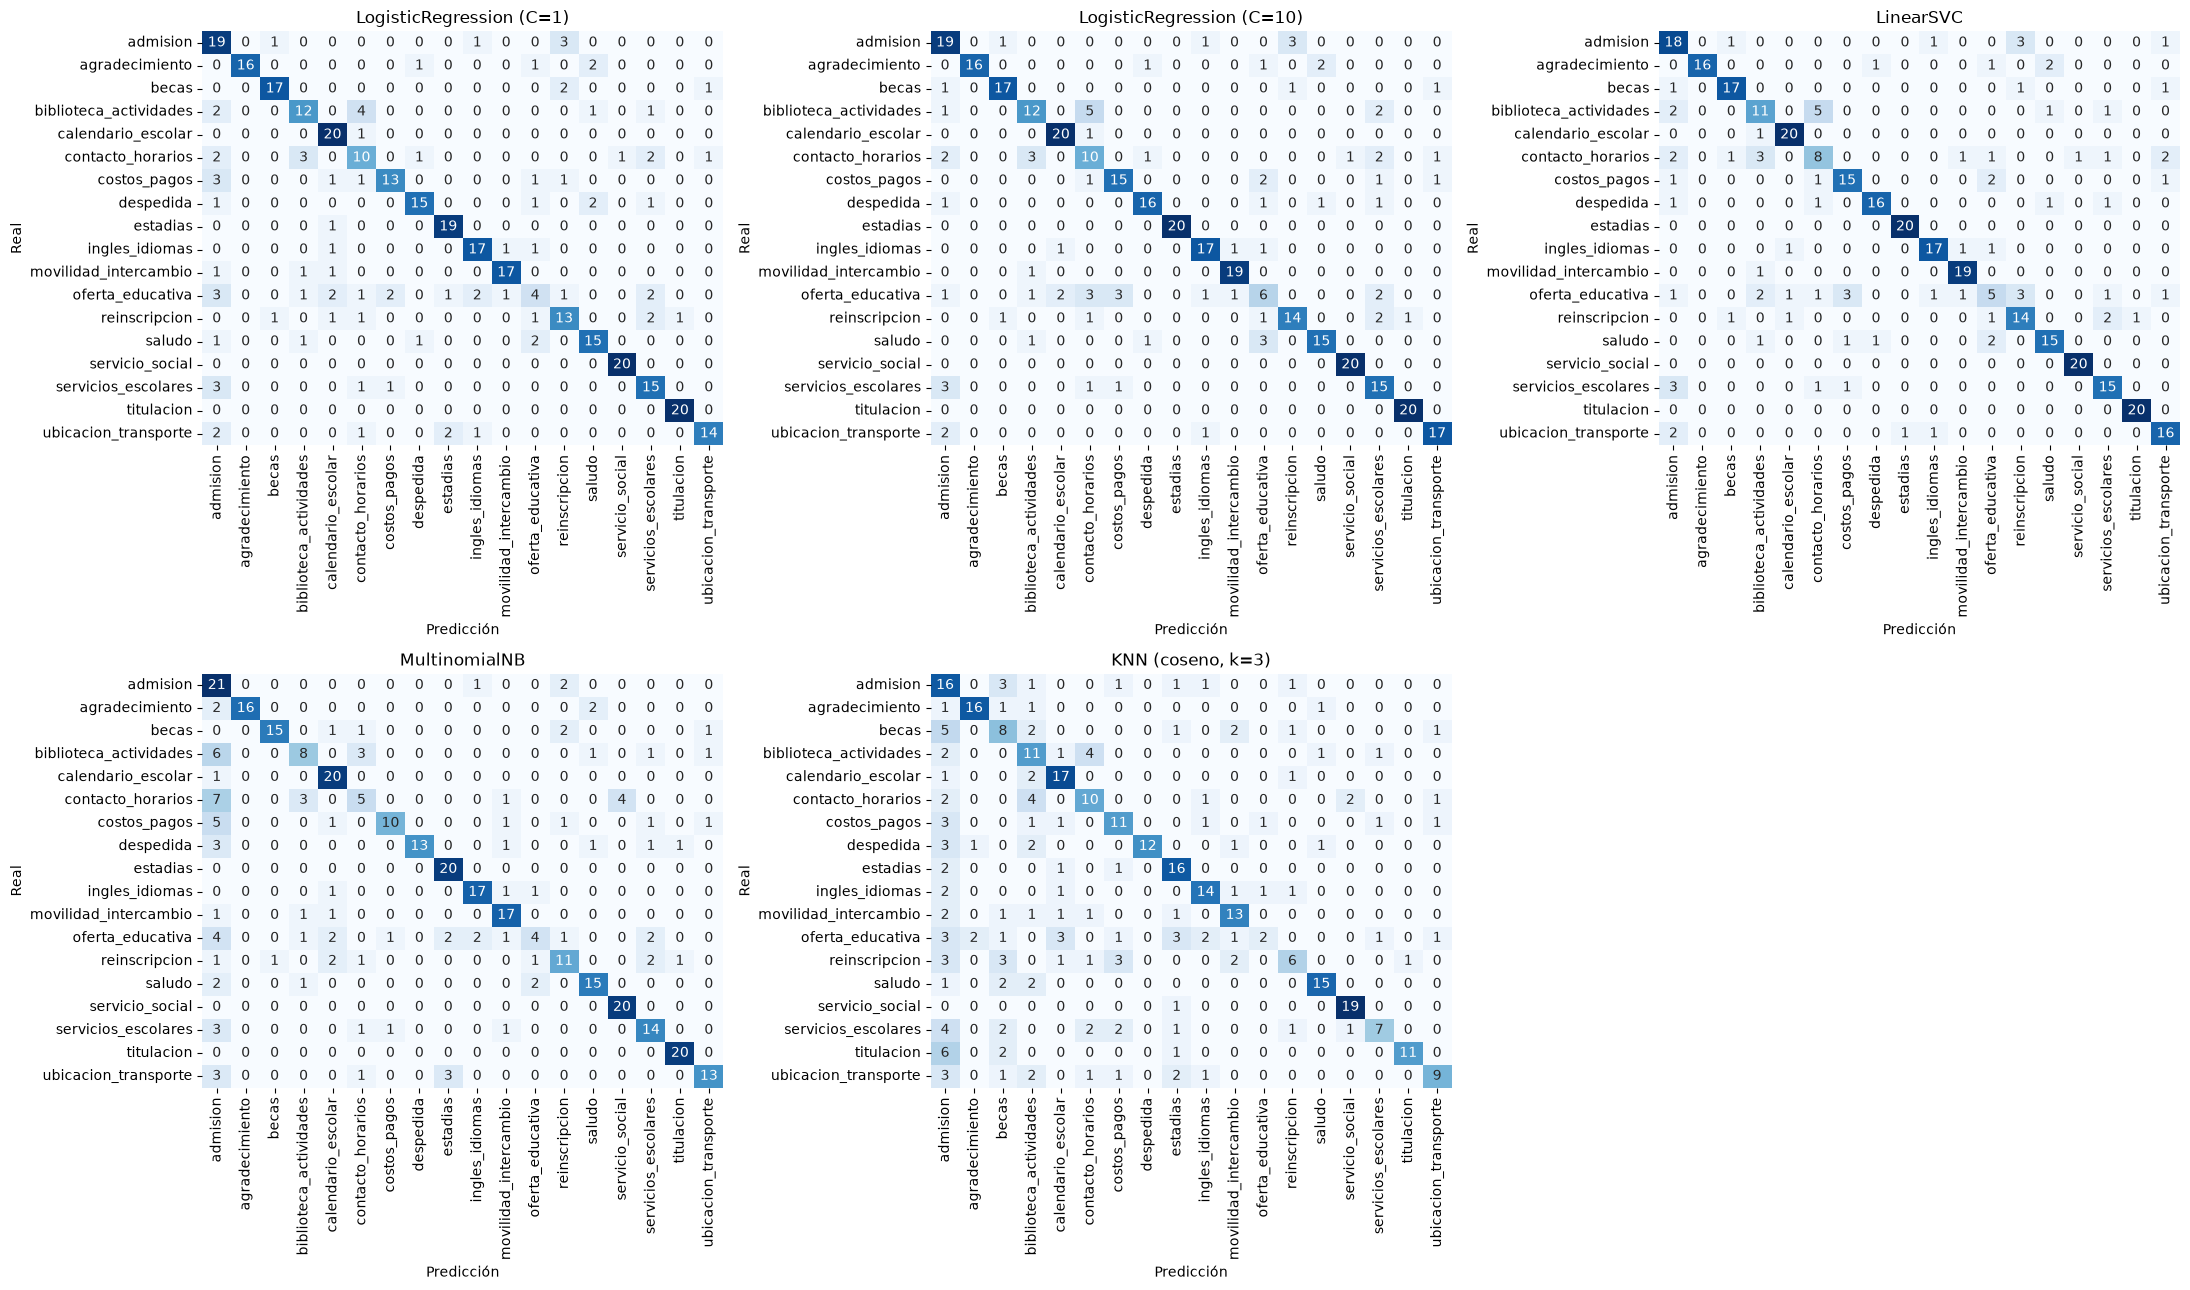

In [5]:
orden = sorted(y.unique())
predicciones = {}

fig, ejes = plt.subplots(2, 3, figsize=(22, 13))
for eje, (nombre, pipe) in zip(ejes.ravel(), pipelines.items()):
    pred = cross_val_predict(pipe, X, y, cv=folds)
    predicciones[nombre] = pred
    cm = confusion_matrix(y, pred, labels=orden)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=orden, yticklabels=orden, ax=eje)
    eje.set_title(nombre)
    eje.set_xlabel("Predicción")
    eje.set_ylabel("Real")
for eje in ejes.ravel()[len(pipelines):]:
    eje.axis("off")

plt.tight_layout()
plt.show()

In [6]:
mejor = resultados.loc[0, "modelo"]
print(f"Reporte del mejor modelo según F1 macro: {mejor}\n")
print(classification_report(y, predicciones[mejor], zero_division=0))

Reporte del mejor modelo según F1 macro: LogisticRegression (C=10)

                        precision    recall  f1-score   support

              admision       0.63      0.79      0.70        24
        agradecimiento       1.00      0.80      0.89        20
                 becas       0.89      0.85      0.87        20
biblioteca_actividades       0.67      0.60      0.63        20
    calendario_escolar       0.87      0.95      0.91        21
     contacto_horarios       0.45      0.50      0.48        20
          costos_pagos       0.79      0.75      0.77        20
             despedida       0.84      0.80      0.82        20
              estadias       1.00      1.00      1.00        20
        ingles_idiomas       0.85      0.85      0.85        20
 movilidad_intercambio       0.90      0.95      0.93        20
      oferta_educativa       0.40      0.30      0.34        20
         reinscripcion       0.78      0.70      0.74        20
                saludo       0.83  

In [7]:
errores = corpus.assign(prediccion=predicciones[mejor])
errores = errores[errores["intencion"] != errores["prediccion"]]
print(f"{len(errores)} errores de {len(corpus)} ejemplos con {mejor}")
display(errores[["texto", "intencion", "prediccion"]])

print("Confusiones más frecuentes (real -> predicción):")
errores[["intencion", "prediccion"]].value_counts().head(8)

77 errores de 365 ejemplos con LogisticRegression (C=10)


,texto,intencion,prediccion
0,¿Cómo me inscribo a la UPQ?,admision,reinscripcion
2,quiero ser alumno nuevo que tengo que hacer,admision,reinscripcion
5,como puedo aplicar para estudiar en la univers...,admision,becas
10,quiero una veca para estudiar,becas,admision
23,beca de transporte,becas,ubicacion_transporte
...,...,...,...
356,que instalaciones tiene la universidad,biblioteca_actividades,contacto_horarios
357,q hay para hacer en la upq ademas de clases,biblioteca_actividades,admision
358,desarrollo humano upq,biblioteca_actividades,contacto_horarios
361,clubes de la universidad,biblioteca_actividades,contacto_horarios


Confusiones más frecuentes (real -> predicción):


intencion               prediccion            
biblioteca_actividades  contacto_horarios         5
admision                reinscripcion             3
saludo                  oferta_educativa          3
oferta_educativa        costos_pagos              3
                        contacto_horarios         3
servicios_escolares     admision                  3
contacto_horarios       biblioteca_actividades    3
agradecimiento          saludo                    2
Name: count, dtype: int64

## Conclusión (corpus completo: 365 ejemplos, 18 intenciones)

**Procedimiento.** Los cinco modelos se evaluaron con el mismo `Pipeline` (TF-IDF de
caracteres `char_wb` 3-5 con `sublinear_tf`) y los mismos 5 folds (`StratifiedKFold`,
`random_state=42`). El TF-IDF se ajusta solo con el entrenamiento de cada fold, para
evitar fuga de datos.

**Resultados (F1 macro ± desviación).** LogisticRegression C=10: 0.781 ± 0.061;
LinearSVC: 0.762 ± 0.056; LogisticRegression C=1: 0.747 ± 0.042; MultinomialNB:
0.694 ± 0.039; KNN: 0.572 ± 0.043.

**Elección: Regresión Logística con C=10.** Obtiene el mejor F1 macro, aunque LinearSVC
queda a menos de una desviación estándar, así que el F1 por sí solo no los separa. Se
elige Regresión Logística porque da probabilidades nativas (`predict_proba`), que necesita
el fallback por umbral, sin calibración adicional. Con 18 intenciones, C=10 supera a C=1
por 0.034, casi una desviación estándar.

**Umbrales** (`scripts/calibrar_umbrales.py`, con `data/fuera_de_alcance.csv`):
`umbral_alto` = 0.66 y `umbral_bajo` = 0.26. El 27 % de las preguntas válidas recibe
respuesta directa con 98 % de acierto, el 54 % pasa por "¿Quisiste decir…?" y el 19 %
cae en fallback; se rechaza el 79 % de las preguntas ajenas que pasan los guardrails.

**Errores.** El modelo falla 77 de 365 ejemplos. Las confusiones se concentran en
intenciones que comparten vocabulario: `biblioteca_actividades` y `contacto_horarios`
(horarios), `admision` y `reinscripcion`, `costos_pagos` y `oferta_educativa`, y saludos
muy cortos ("qué onda", "hey") que casi no aportan n-gramas.